# One fixed AR(3) path: geometric projected subgradient descent

This notebook simulates **one** AR(3) path with **500 retained observations** and uniform innovations on $[-1,1]$. It runs the sphere-projected subgradient method from **one fixed random starting direction**, using the literal step sizes

$$\gamma_t=0.1\,(0.75)^t.$$

The iteration cap is **2,000**, improvement patience is **200**, and the improvement tolerance is $10^{-10}$. The initial step is passed directly to the optimizer, without Lipschitz normalization. All settings and seeds are collected below. Every displayed figure is also saved as PDF and PNG in this notebook's own output folders.

Implementation sources: [simulation and embedding](ar_tools/functions.py), [shared optimizer](ar_tools/descent.py), and the projected subgradient algorithm in the [AR thesis chapter](../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex). The geometric schedule is studied in [Li et al. (2021), §5.2, Theorem 4](https://arxiv.org/pdf/1911.05047#page=17).

In [13]:
import json
import sys
from importlib import reload
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from threadpoolctl import threadpool_limits

AR_CODE_DIR = next(
    (
        candidate.resolve()
        for root in (Path.cwd(), *Path.cwd().parents)
        for candidate in (root / "Code" / "Code_AR_processes", root)
        if (candidate / "ar_tools/functions.py").is_file()
    ),
    None,
)
if AR_CODE_DIR is None:
    raise FileNotFoundError("Could not locate Code/Code_AR_processes.")
PROJECT_ROOT = AR_CODE_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Code.Code_AR_processes.ar_tools import descent as descent_tools
reload(descent_tools)
from Code.Code_AR_processes.ar_tools.descent import projected_subgradient_empirical_width
from Code.Code_AR_processes.ar_tools.functions import (
    coefficients_from_minimizing_direction,
    is_stationary,
    simulate_uniform_ar,
    sliding_window_point_cloud,
)

EXPERIMENT_NAME = "ar3_single_path_geometric_descent"
PDF_DIR = AR_CODE_DIR / "outputs" / "pdfs" / EXPERIMENT_NAME
IMAGE_DIR = AR_CODE_DIR / "outputs" / "images" / EXPERIMENT_NAME
DATA_DIR = AR_CODE_DIR / "outputs" / "csv" / EXPERIMENT_NAME
for directory in (PDF_DIR, IMAGE_DIR, DATA_DIR):
    directory.mkdir(parents=True, exist_ok=True)

np.set_printoptions(precision=8, suppress=True)


## Fixed settings

The coefficient vector is chosen as $(0.5,-0.2,0.1)$. The cell below explicitly computes its companion eigenvalues and checks that their moduli are below one, using [the existing stationarity helper](ar_tools/functions.py). The reported spectral radius is a calculation for this selected vector.

The retained sample follows the simulation convention
$$X_t=0.5X_{t-1}-0.2X_{t-2}+0.1X_{t-3}+\varepsilon_t,\qquad \varepsilon_t\overset{\mathrm{iid}}{\sim}\mathcal U(-1,1).$$
A burn-in of 1,000 observations is discarded by [the shared simulator](ar_tools/functions.py).

In [14]:
T = 1000
p = 3
phi = np.array([0.5, -0.2, 0.1], dtype=float)
burnin = 1_000
process_seed = 20261018
optimizer_seed = 20261019

max_iterations = 2_000
patience = 200
improvement_tolerance = 1e-10
gamma_0 = 0.1
beta = 0.75
embedding_dimension = p + 1

stationary, companion_eigenvalues = is_stationary(phi)
spectral_radius = float(np.max(np.abs(companion_eigenvalues)))
assert len(phi) == p and stationary
print(f"Coefficients: {phi}")
print(f"Companion eigenvalues: {companion_eigenvalues}")
print(f"Companion spectral radius: {spectral_radius:.8f}")
print(f"T = {T}; p = {p}; embedding dimension = {embedding_dimension}")
print(f"Process seed = {process_seed}; optimizer seed = {optimizer_seed}")
print(f"Iteration cap = {max_iterations}; patience = {patience}")
print(f"Actual initial step = {gamma_0}; geometric decay = {beta}")


Coefficients: [ 0.5 -0.2  0.1]
Companion eigenvalues: [ 0.5+0.j        -0. +0.4472136j -0. -0.4472136j]
Companion spectral radius: 0.50000000
T = 1000; p = 3; embedding dimension = 4
Process seed = 20261018; optimizer seed = 20261019
Iteration cap = 2000; patience = 200
Actual initial step = 0.1; geometric decay = 0.75


## Simulate and plot the fixed process

The simulation runs once in this cell. The descent and plotting cells below reuse the resulting `series` and `point_cloud`; they do not generate another path. The embedding uses newest-first windows $(X_t,X_{t-1},X_{t-2},X_{t-3})$, as implemented in [sliding_window_point_cloud](ar_tools/functions.py).

Retained observations: 1000; embedding points: 997


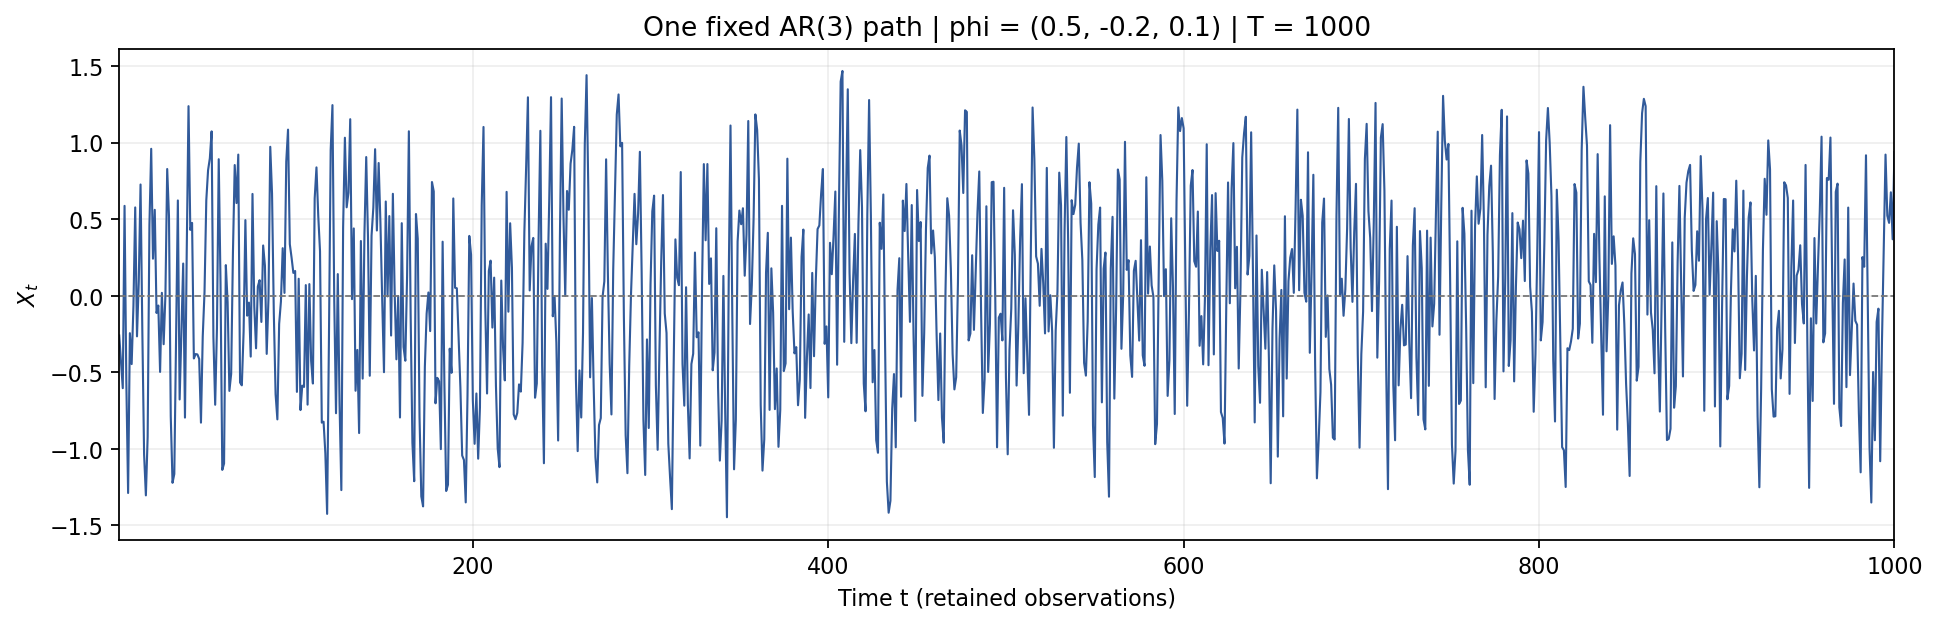

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_single_path_geometric_descent/fixed_ar3_process.pdf


In [15]:
series = simulate_uniform_ar(
    phi=phi,
    sample_size=T,
    burnin=burnin,
    half_width=1.0,
    rng=process_seed,
)
point_cloud = sliding_window_point_cloud(
    series,
    embedding_dimension=embedding_dimension,
    newest_first=True,
)
assert series.shape == (T,)
assert point_cloud.shape == (T - p, embedding_dimension)

process_data = pd.DataFrame({"time": np.arange(1, T + 1), "X_t": series})
process_data.to_csv(DATA_DIR / "process.csv", index=False)
print(f"Retained observations: {len(series)}; embedding points: {len(point_cloud)}")

with plt.rc_context({"font.size": 10, "pdf.fonttype": 42}):
    fig, ax = plt.subplots(figsize=(12, 3.8), constrained_layout=True)
    ax.plot(process_data["time"], series, color="#315a9a", linewidth=0.95)
    ax.axhline(0.0, color="#777777", linewidth=0.8, linestyle="--")
    ax.set(
        xlabel="Time t (retained observations)",
        ylabel=r"$X_t$",
        title=f"One fixed AR(3) path | phi = (0.5, -0.2, 0.1) | T = {T}",
        xlim=(1, T),
    )
    ax.grid(alpha=0.2)
    process_pdf_path = PDF_DIR / "fixed_ar3_process.pdf"
    process_png_path = IMAGE_DIR / "fixed_ar3_process.png"
    fig.savefig(process_pdf_path, bbox_inches="tight")
    fig.savefig(process_png_path, dpi=160, bbox_inches="tight")
    plt.close(fig)
display(Image(filename=str(process_png_path)))
print(f"Saved PDF: {process_pdf_path}")


## Run one projected subgradient descent

For the empirical width and the sphere update, this cell calls the [existing optimizer](ar_tools/descent.py):
$$w_P(u)=\max_{x\in P}\langle x,u\rangle-\min_{x\in P}\langle x,u\rangle,$$
$$g_t=x_{\max,t}-x_{\min,t},\qquad \xi_t=(I-u_tu_t^\top)g_t,\qquad
u_{t+1}=\frac{u_t-\gamma_t\xi_t}{\|u_t-\gamma_t\xi_t\|}.$$
The code below uses $\gamma_t=\gamma_0\beta^t$ with the **literal** $\gamma_0=0.1$.

The shared implementation records $w_P(u_t)$ before taking the next update. Consequently, iteration **0** denotes the initial direction. Patience counts consecutive evaluated directions without a width improvement greater than `improvement_tolerance`; the returned direction is the best recorded direction. These conventions are defined in [projected_subgradient_empirical_width](ar_tools/descent.py).

In [16]:
start_generator = np.random.default_rng(optimizer_seed)
initial_direction = start_generator.normal(size=embedding_dimension)
initial_direction /= np.linalg.norm(initial_direction)

with threadpool_limits(limits=1):
    result = projected_subgradient_empirical_width(
        points=point_cloud,
        iterations=max_iterations,
        initial_step=gamma_0,
        patience=patience,
        improvement_tolerance=improvement_tolerance,
        rng=optimizer_seed,
        initial_direction=initial_direction.copy(),
        step_schedule="geometric",
        geometric_decay=beta,
    )

history = pd.DataFrame({
    "iteration": np.arange(len(result["width_history"])),
    "current_width": result["width_history"],
    "best_recorded_width": result["best_width_history"],
    "step_size": result["step_history"],
})
recorded_improvements = np.r_[True, np.diff(history["best_recorded_width"]) < 0]
last_improvement_iteration = int(history.loc[recorded_improvements, "iteration"].iloc[-1])
best_direction = result["direction"].copy()
if best_direction[0] < 0:
    best_direction *= -1

history.to_csv(DATA_DIR / "iteration_history.csv", index=False)
assert 1 <= len(history) <= max_iterations
assert history["step_size"].iloc[0] == gamma_0
np.testing.assert_allclose(
    history["step_size"].to_numpy(),
    gamma_0 * beta ** history["iteration"].to_numpy(),
    rtol=1e-14,
    atol=0,
)
assert np.all(np.diff(history["best_recorded_width"]) <= 0)
assert np.isclose(np.linalg.norm(best_direction), 1.0)
assert np.isclose(np.ptp(point_cloud @ best_direction), result["minimum_width"])
if result["termination_reason"] == "patience":
    assert int(history["iteration"].iloc[-1]) - last_improvement_iteration == patience

print(f"Evaluated directions: {len(history)} of at most {max_iterations}")
print(f"Stopping reason: {result['termination_reason']}")
print(f"Last recorded improvement: iteration {last_improvement_iteration}")
print(f"Initial width: {history['current_width'].iloc[0]:.12f}")
print(f"Best recorded width: {result['minimum_width']:.12f}")
print(f"Best direction (sign chosen so u_0 >= 0): {best_direction}")


Evaluated directions: 279 of at most 2000
Stopping reason: patience
Last recorded improvement: iteration 78
Initial width: 3.005942013403
Best recorded width: 1.884071454490
Best direction (sign chosen so u_0 >= 0): [ 0.01977725 -0.88721892  0.44837409 -0.10682756]


## Plot the recorded iterations

The upper panel shows the complete recorded run; the lower-left panel enlarges the first 80 evaluated directions. Blue is the current width, orange is the best recorded width, and the dotted marker identifies the last recorded improvement. The lower-right panel shows the actual geometric step sizes on a logarithmic scale.

The plot ends at the recorded stopping iteration. It is not extended to the 2,000-iteration cap after patience stops the run. All traces come from the `result` returned above; plotting does not rerun optimization.

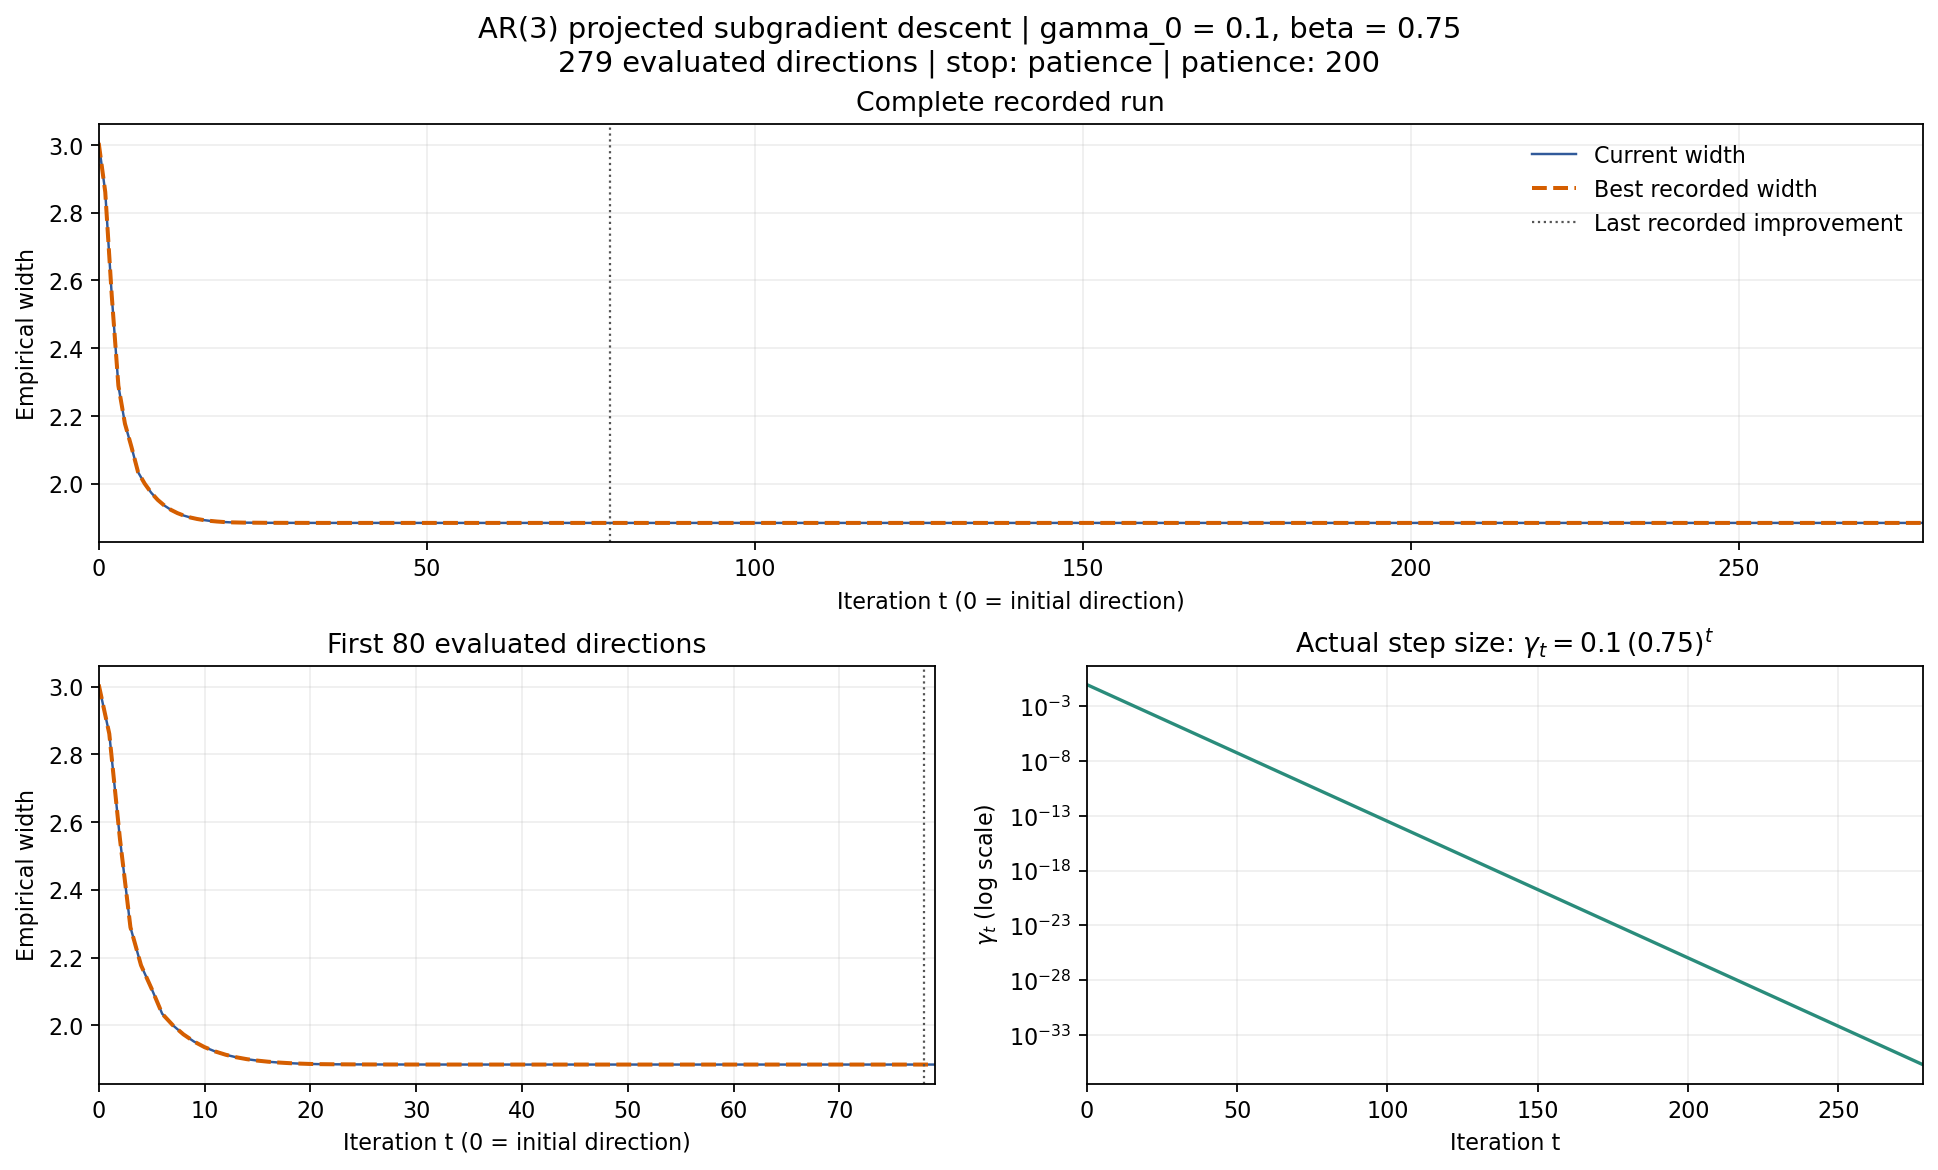

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_single_path_geometric_descent/projected_descent_iterations.pdf


In [17]:
with plt.rc_context({"font.size": 10, "pdf.fonttype": 42}):
    fig = plt.figure(figsize=(12, 7.2), constrained_layout=True)
    grid = fig.add_gridspec(2, 2)
    full_ax = fig.add_subplot(grid[0, :])
    early_ax = fig.add_subplot(grid[1, 0])
    step_ax = fig.add_subplot(grid[1, 1])

    for ax, shown_history, title in (
        (full_ax, history, "Complete recorded run"),
        (early_ax, history.iloc[:80], "First 80 evaluated directions"),
    ):
        ax.plot(
            shown_history["iteration"], shown_history["current_width"],
            color="#315a9a", linewidth=1.1, label="Current width",
        )
        ax.plot(
            shown_history["iteration"], shown_history["best_recorded_width"],
            color="#d55e00", linewidth=1.8, linestyle="--", label="Best recorded width",
        )
        if last_improvement_iteration <= shown_history["iteration"].iloc[-1]:
            ax.axvline(
                last_improvement_iteration, color="#555555", linewidth=1,
                linestyle=":", label="Last recorded improvement",
            )
        ax.set(xlabel="Iteration t (0 = initial direction)", ylabel="Empirical width", title=title)
        ax.set_xlim(0, max(1, int(shown_history["iteration"].iloc[-1])))
        ax.ticklabel_format(axis="y", style="plain", useOffset=False)
        ax.grid(alpha=0.2)
    full_ax.legend(loc="best", frameon=False)

    step_ax.semilogy(history["iteration"], history["step_size"], color="#2a8c7b", linewidth=1.5)
    step_ax.set(
        xlabel="Iteration t", ylabel=r"$\gamma_t$ (log scale)",
        title=r"Actual step size: $\gamma_t=0.1\,(0.75)^t$",
    )
    step_ax.set_xlim(0, max(1, int(history["iteration"].iloc[-1])))
    step_ax.grid(alpha=0.2)
    fig.suptitle(
        f"AR(3) projected subgradient descent | gamma_0 = {gamma_0}, beta = {beta}\n"
        f"{len(history)} evaluated directions | stop: {result['termination_reason']} | patience: {patience}",
        fontsize=13,
    )
    iterations_pdf_path = PDF_DIR / "projected_descent_iterations.pdf"
    iterations_png_path = IMAGE_DIR / "projected_descent_iterations.png"
    fig.savefig(iterations_pdf_path, bbox_inches="tight")
    fig.savefig(iterations_png_path, dpi=160, bbox_inches="tight")
    plt.close(fig)
display(Image(filename=str(iterations_png_path)))
print(f"Saved PDF: {iterations_pdf_path}")


## Returned direction and reproducibility record

For inspection after optimization, transform the best recorded direction into coefficient estimates using $\widehat\phi_j=-\widehat u_j/\widehat u_0$; see the coefficient-recovery remark in the [AR thesis chapter](../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex) and [coefficients_from_minimizing_direction](ar_tools/functions.py). The true coefficients are used only to display this comparison. Neither the initial direction nor the optimizer receives them.

The table reports this single run. All settings, the initial direction, the best direction, and the stopping information are saved beside the process and iteration CSV files.

In [18]:
if not np.isclose(best_direction[0], 0.0):
    estimated_phi = coefficients_from_minimizing_direction(best_direction)
    coefficient_comparison = pd.DataFrame({
        "coefficient": [f"phi_{j}" for j in range(1, p + 1)],
        "true": phi,
        "estimated_from_best_direction": estimated_phi,
    })
    coefficient_comparison.to_csv(DATA_DIR / "coefficient_comparison.csv", index=False)
    display(coefficient_comparison)
else:
    estimated_phi = None
    print("The first direction component is too close to zero for coefficient recovery.")

configuration = {
    "T": T, "p": p, "phi": phi.tolist(), "burnin": burnin,
    "innovations": "iid uniform(-1, 1)",
    "process_seed": process_seed, "optimizer_seed": optimizer_seed,
    "embedding_dimension": embedding_dimension, "newest_first": True,
    "number_of_starts": 1, "max_iterations": max_iterations,
    "patience": patience, "improvement_tolerance": improvement_tolerance,
    "gamma_0": gamma_0, "beta": beta, "step_schedule": "geometric",
    "lipschitz_normalization": False,
    "initial_direction": initial_direction.tolist(),
    "best_direction": best_direction.tolist(),
    "estimated_phi": None if estimated_phi is None else estimated_phi.tolist(),
    "best_recorded_width": float(result["minimum_width"]),
    "evaluated_directions": len(history),
    "last_improvement_iteration": last_improvement_iteration,
    "termination_reason": result["termination_reason"],
    "companion_spectral_radius": spectral_radius,
}
(DATA_DIR / "configuration.json").write_text(json.dumps(configuration, indent=2) + "\n")
print(f"Saved data and settings: {DATA_DIR}")


,coefficient,true,estimated_from_best_direction
0,phi_1,0.5,44.860571
1,phi_2,-0.2,-22.671200
2,phi_3,0.1,5.401536


Saved data and settings: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/csv/ar3_single_path_geometric_descent


## Grid search: achieved minimum-width matrix

Run the proposed grid below on the **same `point_cloud` and the same `initial_direction`** used above. Each pair receives the same 2,000-evaluation cap, improvement patience of 200, and improvement tolerance of $10^{-10}$. The grid contains **45 pairs**. The values of $\gamma_0$ are actual initial steps, with no Lipschitz normalization.

The matrix has **$\gamma_0$ in rows** and **$\beta$ in columns**. Each entry is the best recorded empirical width returned by [the shared projected subgradient optimizer](ar_tools/descent.py); smaller values are better for this fixed optimization problem. The process and starting direction are not regenerated. The original single-run settings and result remain available above.

This is the exploratory grid proposed in our discussion. It includes the authors' full-subgradient presets from [DPCP_RieSub_linear.m](https://github.com/xiao-li-hub/Riemannian-subgradient-methods/blob/master/DPCP_RieSub_linear.m) and [ODL_RieSub_linear.m](https://github.com/xiao-li-hub/Riemannian-subgradient-methods/blob/master/ODL_RieSub_linear.m), together with smaller initial steps and slower decays.

In [19]:
gamma0_grid = np.array([0.003, 0.01, 0.03, 0.1, 0.3], dtype=float)
beta_grid = np.array([0.65, 0.75, 0.90, 0.95, 0.97, 0.99, 0.995, 0.997, 0.999], dtype=float)

assert np.all(np.isfinite(gamma0_grid)) and np.all(gamma0_grid > 0)
assert np.all(np.isfinite(beta_grid)) and np.all((beta_grid > 0) & (beta_grid < 1))
assert len(np.unique(gamma0_grid)) == len(gamma0_grid)
assert len(np.unique(beta_grid)) == len(beta_grid)

shared_start_before_grid = initial_direction.copy()
grid_rows = []
with threadpool_limits(limits=1):
    for grid_gamma0 in gamma0_grid:
        for grid_beta in beta_grid:
            grid_result = projected_subgradient_empirical_width(
                points=point_cloud,
                iterations=max_iterations,
                initial_step=float(grid_gamma0),
                patience=patience,
                improvement_tolerance=improvement_tolerance,
                rng=optimizer_seed,
                initial_direction=initial_direction.copy(),
                step_schedule="geometric",
                geometric_decay=float(grid_beta),
            )
            assert np.isclose(np.linalg.norm(grid_result["direction"]), 1.0)
            np.testing.assert_allclose(
                np.ptp(point_cloud @ grid_result["direction"]),
                grid_result["minimum_width"], rtol=0, atol=1e-12,
            )
            grid_rows.append({
                "gamma_0": float(grid_gamma0),
                "beta": float(grid_beta),
                "minimum_width": float(grid_result["minimum_width"]),
                "evaluated_directions": len(grid_result["width_history"]),
                "termination_reason": grid_result["termination_reason"],
                **{f"u_{j}": float(value) for j, value in enumerate(grid_result["direction"])},
            })

grid_results = pd.DataFrame(grid_rows)
minimum_width_matrix = grid_results.pivot(
    index="gamma_0", columns="beta", values="minimum_width",
).reindex(index=gamma0_grid, columns=beta_grid)

assert len(grid_results) == len(gamma0_grid) * len(beta_grid)
assert np.all(np.isfinite(minimum_width_matrix.to_numpy()))
assert grid_results["evaluated_directions"].between(1, max_iterations).all()
np.testing.assert_array_equal(initial_direction, shared_start_before_grid)
if gamma_0 in gamma0_grid and beta in beta_grid:
    np.testing.assert_allclose(
        minimum_width_matrix.loc[gamma_0, beta],
        result["minimum_width"], rtol=0, atol=1e-12,
    )

grid_results.to_csv(DATA_DIR / "gamma0_beta_grid_results.csv", index=False)
matrix_csv_path = DATA_DIR / "gamma0_beta_minimum_width_matrix.csv"
minimum_width_matrix.to_csv(matrix_csv_path, float_format="%.17g")
grid_configuration = {
    "gamma0_grid": gamma0_grid.tolist(), "beta_grid": beta_grid.tolist(),
    "T": T, "p": p, "phi": phi.tolist(), "burnin": burnin,
    "process_seed": process_seed, "optimizer_seed": optimizer_seed,
    "initial_direction": initial_direction.tolist(), "number_of_starts": 1,
    "max_iterations": max_iterations, "patience": patience,
    "improvement_tolerance": improvement_tolerance,
    "step_schedule": "geometric", "lipschitz_normalization": False,
    "score": "minimum_width returned by projected_subgradient_empirical_width",
}
(DATA_DIR / "gamma0_beta_grid_configuration.json").write_text(
    json.dumps(grid_configuration, indent=2) + "\n",
)

print(f"Completed all {len(grid_results)} pairs on the same path and initial direction.")
print("Rows: actual gamma_0; columns: beta. Smaller widths are better.")
with pd.option_context("display.max_columns", None, "display.precision", 8):
    display(minimum_width_matrix)
print(f"Full-precision matrix CSV: {matrix_csv_path}")


Completed all 45 pairs on the same path and initial direction.
Rows: actual gamma_0; columns: beta. Smaller widths are better.


beta,0.650,0.750,0.900,0.950,0.970,0.990,0.995,0.997,0.999
gamma_0,,,,,,,,,
0.003,2.97574866,2.96736382,2.92615354,2.84711365,2.71853164,2.04981591,1.86295246,1.86298180,1.86304315
0.010,2.93003682,2.90193721,2.72046865,2.32908873,1.98541150,1.86295244,1.86295252,1.86296149,1.86356383
0.030,2.77447260,2.65510717,2.05107353,1.86295244,1.86295244,1.86295244,1.86295263,1.86396111,1.86556847
0.100,2.11937102,1.88407145,1.86295244,1.86295244,1.86295244,1.86295244,1.86295273,1.86394549,1.87097494
0.300,1.99560318,1.97340660,1.86295244,1.86295244,1.86295244,1.86295244,1.86329645,1.86309018,1.90610695


Full-precision matrix CSV: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/csv/ar3_single_path_geometric_descent/gamma0_beta_minimum_width_matrix.csv


## Minimum-width matrix as a heatmap

The heatmap displays the same matrix, with each achieved width printed to eight decimal places. The CSV retains full precision. Both the PDF and PNG are saved automatically; this cell only plots the already computed grid results.

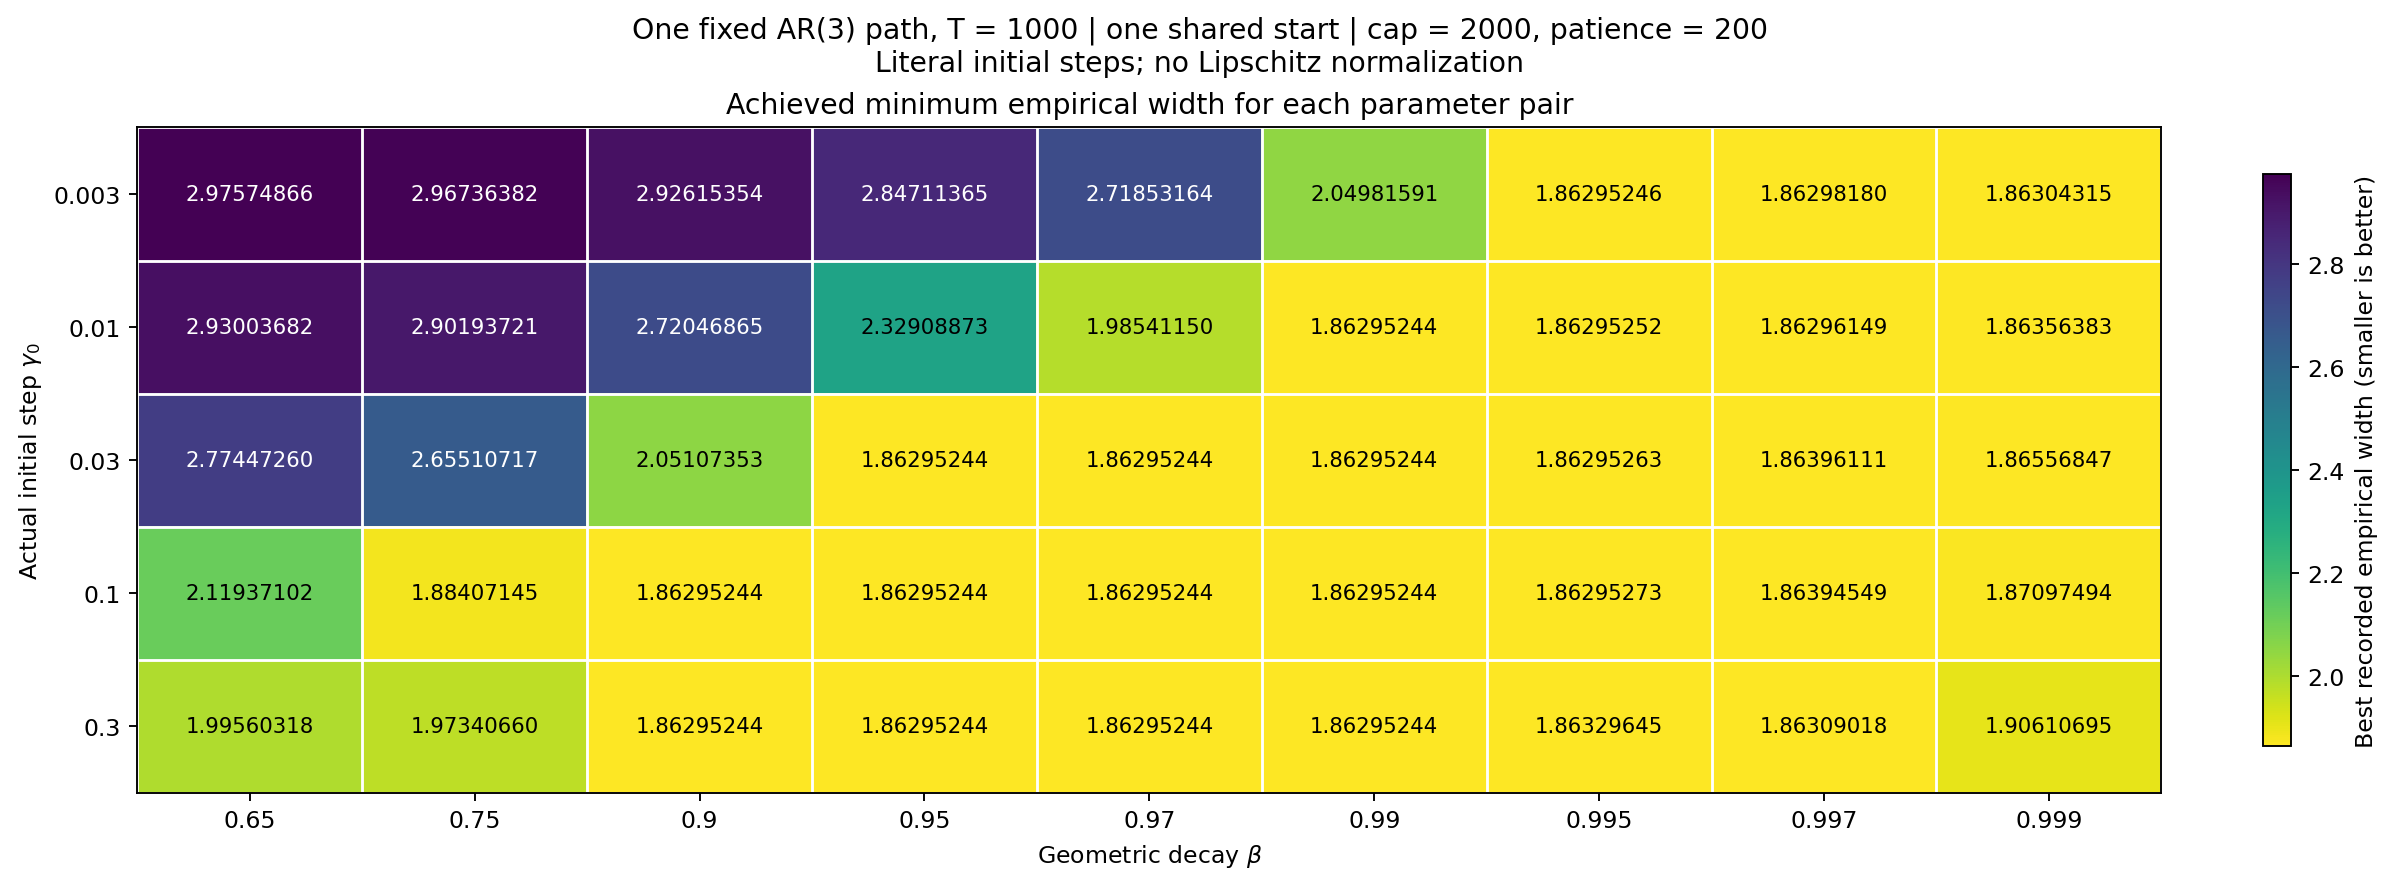

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_single_path_geometric_descent/gamma0_beta_minimum_width_matrix.pdf


In [20]:
matrix_values = minimum_width_matrix.to_numpy()
with plt.rc_context({"font.size": 10, "pdf.fonttype": 42}):
    fig, ax = plt.subplots(figsize=(14, 5.1), constrained_layout=True)
    heatmap = ax.imshow(matrix_values, cmap="viridis_r", aspect="auto")
    ax.set_xticks(np.arange(len(beta_grid)), [f"{value:g}" for value in beta_grid])
    ax.set_yticks(np.arange(len(gamma0_grid)), [f"{value:g}" for value in gamma0_grid])
    ax.set(
        xlabel=r"Geometric decay $\beta$",
        ylabel=r"Actual initial step $\gamma_0$",
        title="Achieved minimum empirical width for each parameter pair",
    )
    for row_index in range(len(gamma0_grid)):
        for column_index in range(len(beta_grid)):
            value = matrix_values[row_index, column_index]
            text_color = "white" if heatmap.norm(value) > 0.5 else "black"
            ax.text(
                column_index, row_index, f"{value:.8f}",
                ha="center", va="center", color=text_color, fontsize=9,
            )
    ax.set_xticks(np.arange(-0.5, len(beta_grid), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(gamma0_grid), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.2)
    ax.tick_params(which="minor", bottom=False, left=False)
    fig.colorbar(heatmap, ax=ax, label="Best recorded empirical width (smaller is better)", shrink=0.86)
    fig.suptitle(
        f"One fixed AR(3) path, T = {T} | one shared start | "
        f"cap = {max_iterations}, patience = {patience}\n"
        "Literal initial steps; no Lipschitz normalization",
        fontsize=12,
    )
    matrix_pdf_path = PDF_DIR / "gamma0_beta_minimum_width_matrix.pdf"
    matrix_png_path = IMAGE_DIR / "gamma0_beta_minimum_width_matrix.png"
    fig.savefig(matrix_pdf_path, bbox_inches="tight")
    fig.savefig(matrix_png_path, dpi=170, bbox_inches="tight")
    plt.close(fig)
display(Image(filename=str(matrix_png_path)))
print(f"Saved PDF: {matrix_pdf_path}")


## Descent for the best grid pair

Select the pair with the smallest **unrounded** `minimum_width` in `grid_results`, then rerun [the shared projected subgradient optimizer](ar_tools/descent.py) to recover its complete trace. The existing process, starting direction, 2,000-evaluation cap, patience of 200, and improvement tolerance are reused. The initial step is used literally, without Lipschitz normalization.

The selected pair is the numerical winner on this fixed path and start. Some grid entries differ by less than the improvement tolerance; the numerical ordering does not establish a meaningful advantage between such close pairs. Selection uses only empirical width, not coefficient error.

For comparison with the preceding global-minimum calculation, recompute the global floating-point width on the same cloud using [exact_empirical_width_low_dimension](ar_tools/lp_widths.py).

In [21]:
from Code.Code_AR_processes.ar_tools.lp_widths import exact_empirical_width_low_dimension

best_grid_row = grid_results.loc[grid_results["minimum_width"].idxmin()].copy()
selected_gamma0 = float(best_grid_row["gamma_0"])
selected_beta = float(best_grid_row["beta"])

with threadpool_limits(limits=1):
    selected_result = projected_subgradient_empirical_width(
        points=point_cloud,
        iterations=max_iterations,
        initial_step=selected_gamma0,
        patience=patience,
        improvement_tolerance=improvement_tolerance,
        rng=optimizer_seed,
        initial_direction=initial_direction.copy(),
        step_schedule="geometric",
        geometric_decay=selected_beta,
    )

selected_history = pd.DataFrame({
    "iteration": np.arange(len(selected_result["width_history"])),
    "current_width": selected_result["width_history"],
    "best_recorded_width": selected_result["best_width_history"],
    "step_size": selected_result["step_history"],
})
selected_improvements = np.r_[True, np.diff(selected_history["best_recorded_width"]) < 0]
selected_last_improvement = int(
    selected_history.loc[selected_improvements, "iteration"].iloc[-1]
)
selected_direction = selected_result["direction"].copy()
if selected_direction[0] < 0:
    selected_direction *= -1

np.testing.assert_allclose(
    selected_result["minimum_width"], best_grid_row["minimum_width"], rtol=0, atol=1e-12,
)
assert len(selected_history) == int(best_grid_row["evaluated_directions"])
assert selected_result["termination_reason"] == best_grid_row["termination_reason"]
np.testing.assert_allclose(
    selected_history["step_size"].to_numpy(),
    selected_gamma0 * selected_beta ** selected_history["iteration"].to_numpy(),
    rtol=1e-14, atol=0,
)
np.testing.assert_allclose(
    np.ptp(point_cloud @ selected_direction), selected_result["minimum_width"],
    rtol=0, atol=1e-12,
)

selected_global_width, selected_global_direction, selected_hull_vertices = (
    exact_empirical_width_low_dimension(point_cloud)
)
selected_width_gap = float(selected_result["minimum_width"] - selected_global_width)
assert selected_width_gap >= -1e-10
if selected_result["termination_reason"] == "patience":
    assert int(selected_history["iteration"].iloc[-1]) - selected_last_improvement == patience

selected_history.to_csv(DATA_DIR / "best_grid_descent_history.csv", index=False)
print(f"Best grid pair: gamma_0 = {selected_gamma0:g}; beta = {selected_beta:g}")
print(f"Best recorded width: {selected_result['minimum_width']:.12f}")
print(f"Global empirical minimum (convex-hull calculation): {selected_global_width:.12f}")
print(f"Absolute gap: {selected_width_gap:.12f}; relative gap: {100 * selected_width_gap / selected_global_width:.6f}%")
print(f"Evaluated directions: {len(selected_history)}; stop: {selected_result['termination_reason']}")
print(f"Last recorded improvement: iteration {selected_last_improvement}")
print(f"Best direction (u_0 >= 0): {selected_direction}")


Best grid pair: gamma_0 = 0.1; beta = 0.9
Best recorded width: 1.862952436122
Global empirical minimum (convex-hull calculation): 1.747611555746
Absolute gap: 0.115340880376; relative gap: 6.599915%
Evaluated directions: 415; stop: patience
Last recorded improvement: iteration 214
Best direction (u_0 >= 0): [ 0.03211422 -0.88291619  0.45005259 -0.12992437]


## Iterations of the selected schedule

The upper panel shows the current and best recorded widths across the full rerun, together with the global empirical minimum. The lower-left panel plots the best recorded width minus that minimum on a logarithmic scale, making any remaining optimization gap visible. The lower-right panel shows the actual step sizes. These plots use `selected_result` and do not rerun optimization.

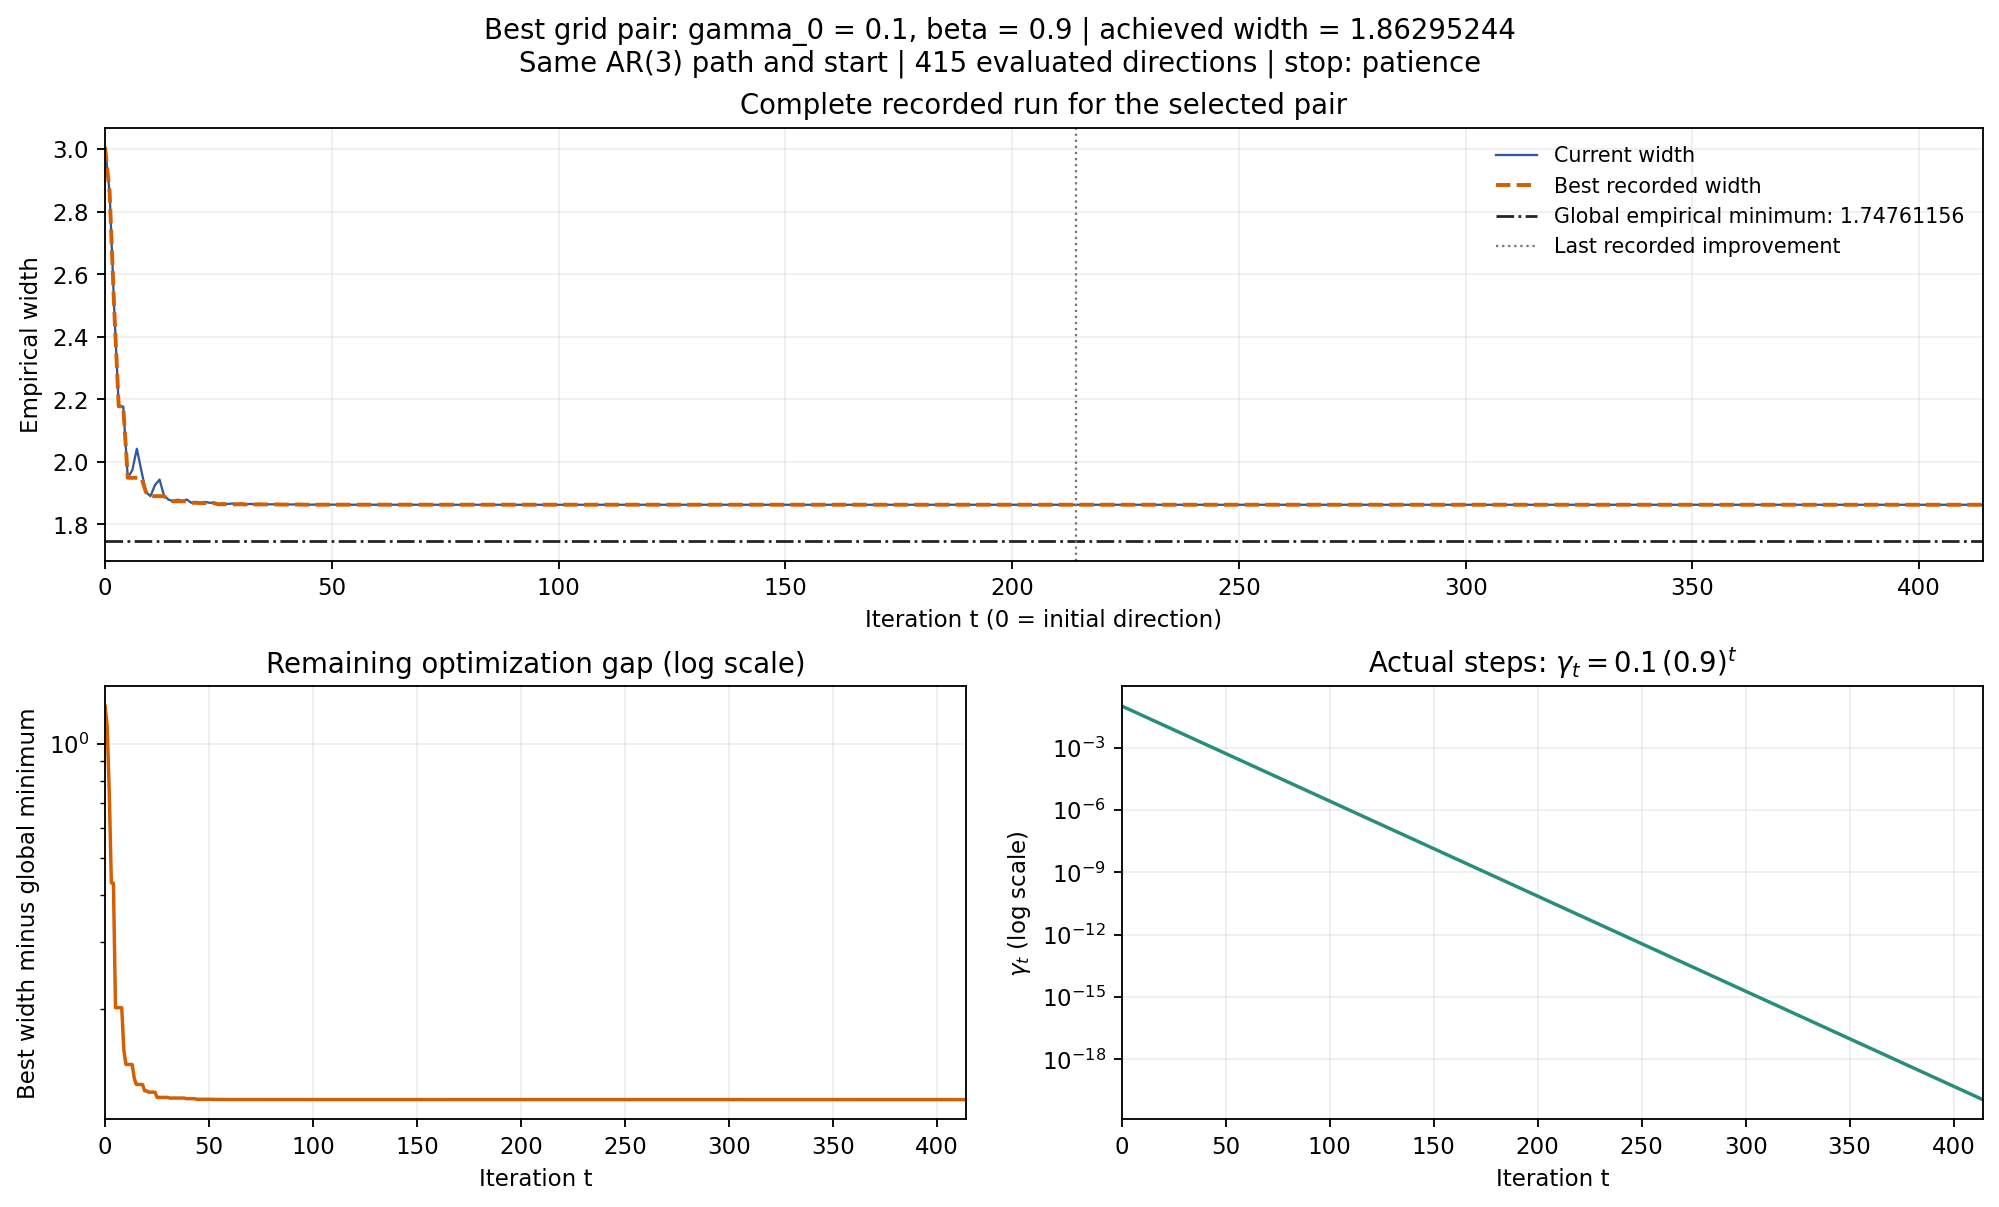

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_single_path_geometric_descent/best_grid_descent_iterations.pdf


In [22]:
with plt.rc_context({"font.size": 10, "pdf.fonttype": 42}):
    fig = plt.figure(figsize=(12, 7.2), constrained_layout=True)
    selected_plot_grid = fig.add_gridspec(2, 2)
    selected_width_ax = fig.add_subplot(selected_plot_grid[0, :])
    selected_gap_ax = fig.add_subplot(selected_plot_grid[1, 0])
    selected_step_ax = fig.add_subplot(selected_plot_grid[1, 1])

    selected_width_ax.plot(
        selected_history["iteration"], selected_history["current_width"],
        color="#315a9a", linewidth=1.0, label="Current width",
    )
    selected_width_ax.plot(
        selected_history["iteration"], selected_history["best_recorded_width"],
        color="#d55e00", linewidth=1.7, linestyle="--", label="Best recorded width",
    )
    selected_width_ax.axhline(
        selected_global_width, color="#222222", linewidth=1.2, linestyle="-.",
        label=f"Global empirical minimum: {selected_global_width:.8f}",
    )
    selected_width_ax.axvline(
        selected_last_improvement, color="#777777", linewidth=1.0, linestyle=":",
        label="Last recorded improvement",
    )
    selected_width_ax.set(
        xlabel="Iteration t (0 = initial direction)", ylabel="Empirical width",
        title="Complete recorded run for the selected pair",
    )
    selected_width_ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    selected_width_ax.legend(loc="best", frameon=False, fontsize=9)

    selected_gap_history = selected_history["best_recorded_width"].to_numpy() - selected_global_width
    # A zero or roundoff-negative gap is omitted from the logarithmic panel.
    selected_positive_gaps = np.where(selected_gap_history > 0, selected_gap_history, np.nan)
    selected_gap_ax.semilogy(
        selected_history["iteration"], selected_positive_gaps,
        color="#d55e00", linewidth=1.5,
    )
    selected_gap_ax.set(
        xlabel="Iteration t", ylabel="Best width minus global minimum",
        title="Remaining optimization gap (log scale)",
    )
    selected_step_ax.semilogy(
        selected_history["iteration"], selected_history["step_size"],
        color="#2a8c7b", linewidth=1.5,
    )
    selected_step_ax.set(
        xlabel="Iteration t", ylabel=r"$\gamma_t$ (log scale)",
        title=rf"Actual steps: $\gamma_t={selected_gamma0:g}\,({selected_beta:g})^t$",
    )
    for selected_ax in (selected_width_ax, selected_gap_ax, selected_step_ax):
        selected_ax.set_xlim(0, max(1, int(selected_history["iteration"].iloc[-1])))
        selected_ax.grid(alpha=0.2)
    fig.suptitle(
        f"Best grid pair: gamma_0 = {selected_gamma0:g}, beta = {selected_beta:g} | "
        f"achieved width = {selected_result['minimum_width']:.8f}\n"
        f"Same AR(3) path and start | {len(selected_history)} evaluated directions | "
        f"stop: {selected_result['termination_reason']}",
        fontsize=12,
    )
    selected_pdf_path = PDF_DIR / "best_grid_descent_iterations.pdf"
    selected_png_path = IMAGE_DIR / "best_grid_descent_iterations.png"
    fig.savefig(selected_pdf_path, bbox_inches="tight")
    fig.savefig(selected_png_path, dpi=165, bbox_inches="tight")
    plt.close(fig)
display(Image(filename=str(selected_png_path)))
print(f"Saved PDF: {selected_pdf_path}")


## Recovered coefficients for the best grid pair

Apply $\widehat\phi_j=-\widehat u_j/\widehat u_0$ to the best recorded direction from **this selected run**. This is implemented by [coefficients_from_minimizing_direction](ar_tools/functions.py) and stated in the coefficient-recovery remark in the [AR thesis chapter](../../Abschlussarbeit_2021/LaTeX/chapters/3_application_to_time_series.tex).

The table compares the recovered coefficients with $(0.5,-0.2,0.1)$. The true vector is used only for this comparison, after selecting the schedule by its achieved empirical width.

In [23]:
if not np.isclose(selected_direction[0], 0.0):
    selected_phi = coefficients_from_minimizing_direction(selected_direction)
    selected_phi_stationary, selected_phi_eigenvalues = is_stationary(selected_phi)
    selected_coefficient_comparison = pd.DataFrame({
        "coefficient": [f"phi_{j}" for j in range(1, p + 1)],
        "true": phi,
        "recovered": selected_phi,
        "error": selected_phi - phi,
    })
    selected_coefficient_comparison.to_csv(
        DATA_DIR / "best_grid_coefficient_comparison.csv", index=False,
    )
    np.testing.assert_allclose(selected_phi, -selected_direction[1:] / selected_direction[0])
    with pd.option_context("display.precision", 8):
        display(selected_coefficient_comparison)
    print(f"Recovered phi = {selected_phi}")
    print(f"Recovered AR coefficients pass the stationarity check: {selected_phi_stationary}")
else:
    selected_phi = None
    selected_phi_stationary = None
    print("The first direction component is too close to zero for coefficient recovery.")

selected_summary = {
    "selection": "smallest unrounded achieved empirical width among grid pairs",
    "grid_pairs": len(grid_results),
    "gamma_0": selected_gamma0, "beta": selected_beta,
    "T": T, "p": p, "true_phi": phi.tolist(),
    "process_seed": process_seed, "optimizer_seed": optimizer_seed,
    "initial_direction": initial_direction.tolist(),
    "best_direction": selected_direction.tolist(),
    "recovered_phi": None if selected_phi is None else selected_phi.tolist(),
    "recovered_phi_stationary": None if selected_phi_stationary is None else bool(selected_phi_stationary),
    "max_iterations": max_iterations, "patience": patience,
    "improvement_tolerance": improvement_tolerance,
    "lipschitz_normalization": False,
    "minimum_width": float(selected_result["minimum_width"]),
    "global_empirical_minimum_width": float(selected_global_width),
    "absolute_optimization_gap": selected_width_gap,
    "relative_optimization_gap_percent": float(100 * selected_width_gap / selected_global_width),
    "evaluated_directions": len(selected_history),
    "termination_reason": selected_result["termination_reason"],
    "last_recorded_improvement_iteration": selected_last_improvement,
}
(DATA_DIR / "best_grid_descent_summary.json").write_text(
    json.dumps(selected_summary, indent=2) + "\n",
)
print(f"Saved selected-run history, coefficient comparison, and summary in {DATA_DIR}")


,coefficient,true,recovered,error
0,phi_1,0.5,27.49300143,26.99300143
1,phi_2,-0.2,-14.01412353,-13.81412353
2,phi_3,0.1,4.04569653,3.94569653


Recovered phi = [ 27.49300143 -14.01412353   4.04569653]
Recovered AR coefficients pass the stationarity check: False
Saved selected-run history, coefficient comparison, and summary in /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/csv/ar3_single_path_geometric_descent
